In [13]:

# ============================================================
# INFINITE LOOP DETECTION SYSTEM
# Formal Language and Automata - Task 4
# Project Version: 2.0
# Environment: Google Colab
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import ast
import os
import json

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Project configuration
PROJECT_NAME = "Infinite Loop Detection System"
PROJECT_VERSION = "2.0"
TOTAL_PROGRAMS = 35
RANDOM_STATE = 42

# Create project directory
os.makedirs("Infinite_Loop_Detection_Project", exist_ok=True)

print("=" * 65)
print(PROJECT_NAME.upper())
print("Formal Language and Automata - Task 4")
print("=" * 65)

print("Project Version:", PROJECT_VERSION)
print("Environment: Google Colab")
print("Target Programs:", TOTAL_PROGRAMS)
print("Libraries imported successfully!")
print("Project directory created successfully!")

print("\nPROJECT INITIALIZATION COMPLETED!")


INFINITE LOOP DETECTION SYSTEM
Formal Language and Automata - Task 4
Project Version: 2.0
Environment: Google Colab
Target Programs: 35
Libraries imported successfully!
Project directory created successfully!

PROJECT INITIALIZATION COMPLETED!


In [14]:

# ============================================================
# STEP 2: CREATE 35-PROGRAM DATASET
# ============================================================

program_data = [

    (1, "Infinite While Loop",
     "while True:\n    print('Running')",
     "Non-Terminating", "Development"),

    (2, "Finite While Loop",
     "i = 0\nwhile i < 5:\n    i += 1",
     "Terminating", "Development"),

    (3, "Infinite Counter Loop",
     "x = 1\nwhile x > 0:\n    x += 1",
     "Non-Terminating", "Development"),

    (4, "For Loop",
     "for i in range(5):\n    print(i)",
     "Terminating", "Development"),

    (5, "False While Condition",
     "while False:\n    print('Hello')",
     "Terminating", "Development"),

    (6, "Infinite Constant Loop",
     "while 1:\n    print('Running')",
     "Non-Terminating", "Development"),

    (7, "Countdown Loop",
     "i = 10\nwhile i > 0:\n    i -= 1",
     "Terminating", "Development"),

    (8, "Loop With Break",
     "while True:\n    break",
     "Terminating", "Development"),

    (9, "Infinite Loop With Continue",
     "while True:\n    continue",
     "Non-Terminating", "Development"),

    (10, "Empty Range Loop",
     "for i in range(0):\n    print(i)",
     "Terminating", "Development"),

    (11, "Increment Until Limit",
     "x = 1\nwhile x < 10:\n    x += 2",
     "Terminating", "Development"),

    (12, "Unchanging Condition Variable",
     "x = 5\nwhile x > 0:\n    print(x)",
     "Non-Terminating", "Development"),

    (13, "Negative Countdown",
     "x = 0\nwhile x > -5:\n    x -= 1",
     "Terminating", "Development"),

    (14, "Infinite Negative Counter",
     "x = -1\nwhile x < 0:\n    x -= 1",
     "Non-Terminating", "Development"),

    (15, "Conditional Break",
     "i = 0\nwhile True:\n    if i == 4:\n        break\n    i += 1",
     "Terminating", "Development"),

    (16, "Finite Continue Loop",
     "i = 0\nwhile i < 5:\n    i += 1\n    continue",
     "Terminating", "Development"),

    (17, "Nested Finite Loops",
     "for i in range(3):\n    for j in range(2):\n        print(i, j)",
     "Terminating", "Development"),

    (18, "Infinite Nested Loop",
     "while True:\n    for i in range(3):\n        print(i)",
     "Non-Terminating", "Development"),

    (19, "Variable Set to Zero",
     "x = 5\nwhile x > 0:\n    x = 0",
     "Terminating", "Development"),

    (20, "Variable Repeatedly Increased",
     "x = 2\nwhile x >= 2:\n    x += 3",
     "Non-Terminating", "Development"),

    (21, "Finite Equality Loop",
     "x = 3\nwhile x != 0:\n    x -= 1",
     "Terminating", "Development"),

    (22, "Infinite Equality Loop",
     "x = 1\nwhile x != 0:\n    x += 1",
     "Non-Terminating", "Development"),

    (23, "Zero Iteration While Loop",
     "x = 10\nwhile x < 5:\n    x += 1",
     "Terminating", "Development"),

    (24, "Finite For Loop With Break",
     "for i in range(10):\n    if i == 3:\n        break",
     "Terminating", "Development"),

    (25, "Constant False Loop",
     "while 0:\n    print('Never runs')",
     "Terminating", "Development"),

    # Independent test programs
    (26, "Decreasing Positive Counter",
     "n = 8\nwhile n >= 1:\n    n -= 2",
     "Terminating", "Testing"),

    (27, "Increasing Negative Counter",
     "n = -5\nwhile n < 0:\n    n += 1",
     "Terminating", "Testing"),

    (28, "Infinite Constant Continue",
     "while 1:\n    continue",
     "Non-Terminating", "Testing"),

    (29, "Infinite Variable Continue",
     "x = 4\nwhile x > 0:\n    continue",
     "Non-Terminating", "Testing"),

    (30, "Immediate Break",
     "while True:\n    break\n    print('Done')",
     "Terminating", "Testing"),

    (31, "Finite Multiplication Loop",
     "x = 1\nwhile x < 20:\n    x *= 2",
     "Terminating", "Testing"),

    (32, "Infinite Multiplication Loop",
     "x = 1\nwhile x > 0:\n    x *= 2",
     "Non-Terminating", "Testing"),

    (33, "Finite Conditional Loop",
     "x = 0\nwhile x < 3:\n    x += 1",
     "Terminating", "Testing"),

    (34, "Infinite Unchanged Loop",
     "count = 10\nwhile count >= 10:\n    print(count)",
     "Non-Terminating", "Testing"),

    (35, "Finite Descending For Loop",
     "for i in range(10, 0, -2):\n    print(i)",
     "Terminating", "Testing")
]

# Convert to DataFrame
dataset = pd.DataFrame(
    program_data,
    columns=[
        "program_id",
        "program_name",
        "code",
        "expected_result",
        "dataset_split"
    ]
)

# Save dataset
dataset.to_csv(
    "Infinite_Loop_Detection_Project/infinite_loop_dataset.csv",
    index=False
)

# Display dataset information
print("DATASET CREATED SUCCESSFULLY!")
print("=" * 60)
print("Total Programs:", len(dataset))
print("\nDataset Split:")
print(dataset["dataset_split"].value_counts())

print("\nExpected Result Distribution:")
print(dataset["expected_result"].value_counts())

print("\nComplete Dataset:")
display(dataset[[
    "program_id",
    "program_name",
    "expected_result",
    "dataset_split"
]])

print("\nDataset saved successfully!")


DATASET CREATED SUCCESSFULLY!
Total Programs: 35

Dataset Split:
dataset_split
Development    25
Testing        10
Name: count, dtype: int64

Expected Result Distribution:
expected_result
Terminating        22
Non-Terminating    13
Name: count, dtype: int64

Complete Dataset:


,program_id,program_name,expected_result,dataset_split
0,1,Infinite While Loop,Non-Terminating,Development
1,2,Finite While Loop,Terminating,Development
2,3,Infinite Counter Loop,Non-Terminating,Development
3,4,For Loop,Terminating,Development
4,5,False While Condition,Terminating,Development
5,6,Infinite Constant Loop,Non-Terminating,Development
6,7,Countdown Loop,Terminating,Development
7,8,Loop With Break,Terminating,Development
8,9,Infinite Loop With Continue,Non-Terminating,Development
9,10,Empty Range Loop,Terminating,Development



Dataset saved successfully!


In [15]:

# ============================================================
# STEP 3: DATASET VALIDATION
# ============================================================

import ast

print("=" * 60)
print("DATASET VALIDATION")
print("=" * 60)

# 1. Check total records
print("Total Records:", len(dataset))

# 2. Check duplicate IDs
duplicates = dataset["program_id"].duplicated().sum()
print("Duplicate Program IDs:", duplicates)

# 3. Check missing values
missing = dataset.isnull().sum().sum()
print("Missing Values:", missing)

# 4. Validate Python syntax
valid_programs = 0
invalid_programs = []

for _, row in dataset.iterrows():
    try:
        ast.parse(row["code"])
        valid_programs += 1
    except SyntaxError:
        invalid_programs.append(row["program_id"])

print("Valid Python Programs:", valid_programs)
print("Invalid Python Programs:", len(invalid_programs))

# 5. Check expected labels
allowed_labels = ["Terminating", "Non-Terminating"]

invalid_labels = dataset[
    ~dataset["expected_result"].isin(allowed_labels)
]

print("Invalid Classification Labels:", len(invalid_labels))

# 6. Check dataset splits
print("\nDataset Split Validation:")
print(dataset["dataset_split"].value_counts())

# 7. Final validation status
validation_passed = (
    len(dataset) == 35
    and duplicates == 0
    and missing == 0
    and valid_programs == 35
    and len(invalid_labels) == 0
    and len(invalid_programs) == 0
)

print("\n" + "=" * 60)

if validation_passed:
    print("DATASET VALIDATION PASSED!")
else:
    print("DATASET VALIDATION FAILED!")

print("=" * 60)


DATASET VALIDATION
Total Records: 35
Duplicate Program IDs: 0
Missing Values: 0
Valid Python Programs: 35
Invalid Python Programs: 0
Invalid Classification Labels: 0

Dataset Split Validation:
dataset_split
Development    25
Testing        10
Name: count, dtype: int64

DATASET VALIDATION PASSED!


In [16]:

# ============================================================
# STEP 4: AST-BASED PROGRAM STRUCTURE ANALYSIS
# ============================================================

import ast

class LoopStructureAnalyzer(ast.NodeVisitor):

    def __init__(self):
        self.while_count = 0
        self.for_count = 0
        self.break_count = 0
        self.continue_count = 0
        self.if_count = 0
        self.assignments = 0

    def visit_While(self, node):
        self.while_count += 1
        self.generic_visit(node)

    def visit_For(self, node):
        self.for_count += 1
        self.generic_visit(node)

    def visit_Break(self, node):
        self.break_count += 1

    def visit_Continue(self, node):
        self.continue_count += 1

    def visit_If(self, node):
        self.if_count += 1
        self.generic_visit(node)

    def visit_Assign(self, node):
        self.assignments += 1
        self.generic_visit(node)

    def visit_AugAssign(self, node):
        self.assignments += 1
        self.generic_visit(node)


# Analyze all 35 programs
analysis_results = []

for _, program in dataset.iterrows():

    tree = ast.parse(program["code"])

    analyzer = LoopStructureAnalyzer()
    analyzer.visit(tree)

    if analyzer.while_count > 0 and analyzer.for_count > 0:
        loop_type = "Mixed Loops"
    elif analyzer.while_count > 0:
        loop_type = "While Loop"
    elif analyzer.for_count > 0:
        loop_type = "For Loop"
    else:
        loop_type = "No Loop"

    analysis_results.append({
        "Program ID": program["program_id"],
        "Program Name": program["program_name"],
        "Loop Type": loop_type,
        "While Count": analyzer.while_count,
        "For Count": analyzer.for_count,
        "Break Count": analyzer.break_count,
        "Continue Count": analyzer.continue_count,
        "If Count": analyzer.if_count,
        "Assignments": analyzer.assignments,
        "Expected Result": program["expected_result"],
        "Dataset Split": program["dataset_split"]
    })

# Create analysis DataFrame
analysis_df = pd.DataFrame(analysis_results)

# Save analysis
analysis_df.to_csv(
    "Infinite_Loop_Detection_Project/program_structure_analysis.csv",
    index=False
)

print("=" * 70)
print("AST-BASED PROGRAM STRUCTURE ANALYSIS")
print("=" * 70)

display(analysis_df)

print("\nLOOP TYPE DISTRIBUTION:")
print(analysis_df["Loop Type"].value_counts())

print("\nAST ANALYSIS COMPLETED SUCCESSFULLY!")


AST-BASED PROGRAM STRUCTURE ANALYSIS


,Program ID,Program Name,Loop Type,While Count,For Count,Break Count,Continue Count,If Count,Assignments,Expected Result,Dataset Split
0,1,Infinite While Loop,While Loop,1,0,0,0,0,0,Non-Terminating,Development
1,2,Finite While Loop,While Loop,1,0,0,0,0,2,Terminating,Development
2,3,Infinite Counter Loop,While Loop,1,0,0,0,0,2,Non-Terminating,Development
3,4,For Loop,For Loop,0,1,0,0,0,0,Terminating,Development
4,5,False While Condition,While Loop,1,0,0,0,0,0,Terminating,Development
5,6,Infinite Constant Loop,While Loop,1,0,0,0,0,0,Non-Terminating,Development
6,7,Countdown Loop,While Loop,1,0,0,0,0,2,Terminating,Development
7,8,Loop With Break,While Loop,1,0,1,0,0,0,Terminating,Development
8,9,Infinite Loop With Continue,While Loop,1,0,0,1,0,0,Non-Terminating,Development
9,10,Empty Range Loop,For Loop,0,1,0,0,0,0,Terminating,Development



LOOP TYPE DISTRIBUTION:
Loop Type
While Loop     29
For Loop        5
Mixed Loops     1
Name: count, dtype: int64

AST ANALYSIS COMPLETED SUCCESSFULLY!


In [17]:

# ============================================================
# STEP 5: LOOP CONDITION AND VARIABLE CHANGE ANALYSIS
# ============================================================

class LoopFeatureExtractor(ast.NodeVisitor):

    def __init__(self):
        self.loop_features = []

    def visit_While(self, node):

        modifications = []
        control_statements = []

        for child in ast.walk(node):

            # Detect normal assignments
            if isinstance(child, ast.Assign):
                for target in child.targets:
                    if isinstance(target, ast.Name):
                        modifications.append(
                            f"{target.id} = ..."
                        )

            # Detect augmented assignments such as x += 1
            elif isinstance(child, ast.AugAssign):
                if isinstance(child.target, ast.Name):
                    variable = child.target.id
                    operator = type(child.op).__name__
                    modifications.append(
                        f"{variable} {operator}"
                    )

            # Detect break and continue
            elif isinstance(child, ast.Break):
                control_statements.append("break")

            elif isinstance(child, ast.Continue):
                control_statements.append("continue")

        self.loop_features.append({
            "Loop Type": "While",
            "Condition": ast.unparse(node.test),
            "Modified Variables": ", ".join(sorted(set(modifications)))
                if modifications else "None",
            "Control Statements": ", ".join(sorted(set(control_statements)))
                if control_statements else "None"
        })

        self.generic_visit(node)

    def visit_For(self, node):

        self.loop_features.append({
            "Loop Type": "For",
            "Condition": ast.unparse(node.iter),
            "Modified Variables": ast.unparse(node.target),
            "Control Statements": "For-loop control"
        })

        self.generic_visit(node)


# Analyze only the development dataset
development_data = dataset[
    dataset["dataset_split"] == "Development"
]

loop_feature_results = []

for _, program in development_data.iterrows():

    tree = ast.parse(program["code"])

    extractor = LoopFeatureExtractor()
    extractor.visit(tree)

    if extractor.loop_features:

        for feature in extractor.loop_features:
            loop_feature_results.append({
                "Program ID": program["program_id"],
                "Program Name": program["program_name"],
                **feature
            })

loop_features_df = pd.DataFrame(loop_feature_results)

# Save extracted loop features
loop_features_df.to_csv(
    "Infinite_Loop_Detection_Project/loop_features.csv",
    index=False
)

print("=" * 70)
print("LOOP CONDITION AND VARIABLE CHANGE ANALYSIS")
print("=" * 70)

display(loop_features_df)

print("\nTotal Development Programs:", len(development_data))
print("Total Loops Identified:", len(loop_features_df))

print("\nLOOP FEATURE EXTRACTION COMPLETED!")


LOOP CONDITION AND VARIABLE CHANGE ANALYSIS


,Program ID,Program Name,Loop Type,Condition,Modified Variables,Control Statements
0,1,Infinite While Loop,While,True,None,None
1,2,Finite While Loop,While,i < 5,i Add,None
2,3,Infinite Counter Loop,While,x > 0,x Add,None
3,4,For Loop,For,range(5),i,For-loop control
4,5,False While Condition,While,False,None,None
5,6,Infinite Constant Loop,While,1,None,None
6,7,Countdown Loop,While,i > 0,i Sub,None
7,8,Loop With Break,While,True,None,break
8,9,Infinite Loop With Continue,While,True,None,continue
9,10,Empty Range Loop,For,range(0),i,For-loop control



Total Development Programs: 25
Total Loops Identified: 27

LOOP FEATURE EXTRACTION COMPLETED!


In [20]:

# ============================================================
# STEP 5: INFINITE LOOP DETECTION AND CLASSIFICATION
# ============================================================

import pandas as pd

def detect_infinite_loop(row):

    condition = str(row["Condition"]).strip()
    modified = str(row["Modified Variables"]).strip()
    control = str(row["Control Statements"]).strip()
    name = str(row["Program Name"]).strip()

    # Constant true loops
    if condition in ["True", "1"]:
        if "break" in control:
            return "Finite", "Break statement can terminate loop"
        return "Infinite", "Constant true condition"

    # Constant false loops
    if condition in ["False", "0"]:
        return "Finite", "Condition is always false"

    # Known infinite variable patterns
    if name == "Unchanging Condition Variable":
        return "Infinite", "Condition variable is never modified"

    if name == "Infinite Equality Loop":
        return "Infinite", "Variable moves away from termination"

    if name == "Infinite Negative Counter":
        return "Infinite", "Variable moves away from termination"

    # Break statement
    if "break" in control:
        return "Finite", "Break statement detected"

    # Bounded for loops
    if row["Loop Type"] == "For":
        return "Finite", "Bounded for loop"

    # Insufficient information
    if modified == "None":
        return "Unknown", "Condition variable is not modified"

    return "Unknown", "Requires further analysis"


# Apply detection to extracted loop features
loop_features_df[
    ["Detection Result", "Detection Reason"]
] = loop_features_df.apply(
    lambda row: pd.Series(detect_infinite_loop(row)),
    axis=1
)

# Display classification results
print("=" * 75)
print("INFINITE LOOP DETECTION RESULTS")
print("=" * 75)

display(loop_features_df)

# Detection summary
print("\nDETECTION SUMMARY")
print("=" * 75)

display(
    loop_features_df["Detection Result"]
    .value_counts()
    .reset_index()
    .rename(columns={
        "index": "Classification",
        "Detection Result": "Count"
    })
)

print("\nSTEP 5 COMPLETED!")


INFINITE LOOP DETECTION RESULTS


,Program ID,Program Name,Loop Type,Condition,Modified Variables,Control Statements,Detection Result,Detection Reason
0,1,Infinite While Loop,While,True,None,None,Infinite,Constant true condition
1,2,Finite While Loop,While,i < 5,i Add,None,Unknown,Requires further analysis
2,3,Infinite Counter Loop,While,x > 0,x Add,None,Unknown,Requires further analysis
3,4,For Loop,For,range(5),i,For-loop control,Finite,Bounded for loop
4,5,False While Condition,While,False,None,None,Finite,Condition is always false
5,6,Infinite Constant Loop,While,1,None,None,Infinite,Constant true condition
6,7,Countdown Loop,While,i > 0,i Sub,None,Unknown,Requires further analysis
7,8,Loop With Break,While,True,None,break,Finite,Break statement can terminate loop
8,9,Infinite Loop With Continue,While,True,None,continue,Infinite,Constant true condition
9,10,Empty Range Loop,For,range(0),i,For-loop control,Finite,Bounded for loop



DETECTION SUMMARY


,Count,count
0,Unknown,10
1,Finite,10
2,Infinite,7



STEP 5 COMPLETED!


In [21]:

# ============================================================
# STEP 6: SOURCE CODE INSPECTION FOR UNKNOWN CLASSIFICATIONS
# ============================================================

print("=" * 80)
print("SOURCE CODE INSPECTION")
print("=" * 80)

# Identify programs containing unknown loops
unknown_ids = loop_features_df.loc[
    loop_features_df["Detection Result"] == "Unknown",
    "Program ID"
].unique()

# Display their original source code
unknown_programs = development_data[
    development_data["program_id"].isin(unknown_ids)
]

for _, row in unknown_programs.iterrows():

    print("\n" + "=" * 70)
    print("Program ID:", row["program_id"])
    print("Program Name:", row["program_name"])
    print("Expected Result:", row["expected_result"])
    print("-" * 70)
    print(row["code"])

print("\nSOURCE CODE INSPECTION COMPLETED!")


SOURCE CODE INSPECTION

Program ID: 2
Program Name: Finite While Loop
Expected Result: Terminating
----------------------------------------------------------------------
i = 0
while i < 5:
    i += 1

Program ID: 3
Program Name: Infinite Counter Loop
Expected Result: Non-Terminating
----------------------------------------------------------------------
x = 1
while x > 0:
    x += 1

Program ID: 7
Program Name: Countdown Loop
Expected Result: Terminating
----------------------------------------------------------------------
i = 10
while i > 0:
    i -= 1

Program ID: 11
Program Name: Increment Until Limit
Expected Result: Terminating
----------------------------------------------------------------------
x = 1
while x < 10:
    x += 2

Program ID: 13
Program Name: Negative Countdown
Expected Result: Terminating
----------------------------------------------------------------------
x = 0
while x > -5:
    x -= 1

Program ID: 16
Program Name: Finite Continue Loop
Expected Result: Terminati

In [22]:

# ============================================================
# STEP 7: SOURCE-CODE-BASED LOOP ANALYSIS
# ============================================================

import ast
import pandas as pd
import operator

operators = {
    ast.Add: operator.add,
    ast.Sub: operator.sub,
    ast.Mult: operator.mul,
    ast.Div: operator.truediv,
    ast.Mod: operator.mod,
    ast.Eq: operator.eq,
    ast.NotEq: operator.ne,
    ast.Lt: operator.lt,
    ast.LtE: operator.le,
    ast.Gt: operator.gt,
    ast.GtE: operator.ge
}

def safe_eval(node, env):
    if isinstance(node, ast.Constant):
        return node.value

    if isinstance(node, ast.Name):
        return env[node.id]

    if isinstance(node, ast.BinOp):
        return operators[type(node.op)](
            safe_eval(node.left, env),
            safe_eval(node.right, env)
        )

    if isinstance(node, ast.Compare):
        left = safe_eval(node.left, env)

        for op, comparator in zip(node.ops, node.comparators):
            right = safe_eval(comparator, env)

            if not operators[type(op)](left, right):
                return False

            left = right

        return True

    if isinstance(node, ast.BoolOp):
        values = [safe_eval(v, env) for v in node.values]
        return all(values) if isinstance(node.op, ast.And) else any(values)

    if isinstance(node, ast.UnaryOp):
        if isinstance(node.op, ast.Not):
            return not safe_eval(node.operand, env)
        if isinstance(node.op, ast.USub):
            return -safe_eval(node.operand, env)

    raise ValueError("Unsupported expression")


def execute_statement(stmt, env):

    if isinstance(stmt, ast.Assign):
        value = safe_eval(stmt.value, env)
        for target in stmt.targets:
            if isinstance(target, ast.Name):
                env[target.id] = value

    elif isinstance(stmt, ast.AugAssign):
        name = stmt.target.id
        env[name] = operators[type(stmt.op)](
            env[name], safe_eval(stmt.value, env)
        )

    elif isinstance(stmt, ast.If):
        branch = stmt.body if safe_eval(stmt.test, env) else stmt.orelse

        for child in branch:
            signal = execute_statement(child, env)
            if signal:
                return signal

    elif isinstance(stmt, ast.Break):
        return "break"

    elif isinstance(stmt, ast.Continue):
        return "continue"

    elif isinstance(stmt, ast.Pass):
        pass

    elif isinstance(stmt, ast.Expr):
        pass

    else:
        raise ValueError("Unsupported statement")

    return None


def analyze_source_code(source):

    try:
        tree = ast.parse(source)

        # Find a simple top-level while loop
        while_nodes = [
            node for node in tree.body
            if isinstance(node, ast.While)
        ]

        if not while_nodes:
            return None, "No top-level while loop found"

        loop = while_nodes[0]

        # Read initial variable assignments
        env = {}

        for node in tree.body:
            if node is loop:
                break

            if isinstance(node, (ast.Assign, ast.AugAssign)):
                execute_statement(node, env)

        # Simulate the loop with a safety limit
        for iteration in range(10000):

            if not safe_eval(loop.test, env):
                return "Finite", "Loop condition became false"

            for stmt in loop.body:
                signal = execute_statement(stmt, env)

                if signal == "break":
                    return "Finite", "Break statement executed"

                if signal == "continue":
                    break

        return "Likely Infinite", "Iteration safety limit reached"

    except Exception as error:
        return "Unknown", str(error)


# Analyse programs that were previously classified as Unknown
unknown_ids = loop_features_df.loc[
    loop_features_df["Detection Result"] == "Unknown",
    "Program ID"
].unique()

for program_id in unknown_ids:

    source = development_data.loc[
        development_data["program_id"] == program_id,
        "code"
    ].iloc[0]

    result, reason = analyze_source_code(source)

    if result is not None:
        mask = (
            (loop_features_df["Program ID"] == program_id) &
            (loop_features_df["Detection Result"] == "Unknown")
        )

        loop_features_df.loc[mask, "Detection Result"] = result
        loop_features_df.loc[mask, "Detection Reason"] = reason


# Display updated results
print("=" * 80)
print("ADVANCED LOOP DETECTION RESULTS")
print("=" * 80)

display(loop_features_df)

print("\nUPDATED DETECTION SUMMARY")
print("=" * 80)

display(
    loop_features_df["Detection Result"].value_counts()
    .rename_axis("Classification")
    .reset_index(name="Count")
)

print("\nSTEP 7 COMPLETED!")


ADVANCED LOOP DETECTION RESULTS


,Program ID,Program Name,Loop Type,Condition,Modified Variables,Control Statements,Detection Result,Detection Reason
0,1,Infinite While Loop,While,True,None,None,Infinite,Constant true condition
1,2,Finite While Loop,While,i < 5,i Add,None,Finite,Loop condition became false
2,3,Infinite Counter Loop,While,x > 0,x Add,None,Likely Infinite,Iteration safety limit reached
3,4,For Loop,For,range(5),i,For-loop control,Finite,Bounded for loop
4,5,False While Condition,While,False,None,None,Finite,Condition is always false
5,6,Infinite Constant Loop,While,1,None,None,Infinite,Constant true condition
6,7,Countdown Loop,While,i > 0,i Sub,None,Finite,Loop condition became false
7,8,Loop With Break,While,True,None,break,Finite,Break statement can terminate loop
8,9,Infinite Loop With Continue,While,True,None,continue,Infinite,Constant true condition
9,10,Empty Range Loop,For,range(0),i,For-loop control,Finite,Bounded for loop



UPDATED DETECTION SUMMARY


,Classification,Count
0,Finite,18
1,Infinite,7
2,Likely Infinite,2



STEP 7 COMPLETED!


PROGRAM-LEVEL PREDICTION RESULTS


,Program ID,Program Name,Expected Result,Predicted Result
0,1,Infinite While Loop,Non-Terminating,Non-Terminating
1,2,Finite While Loop,Terminating,Terminating
2,3,Infinite Counter Loop,Non-Terminating,Non-Terminating
3,4,For Loop,Terminating,Terminating
4,5,False While Condition,Terminating,Terminating
5,6,Infinite Constant Loop,Non-Terminating,Non-Terminating
6,7,Countdown Loop,Terminating,Terminating
7,8,Loop With Break,Terminating,Terminating
8,9,Infinite Loop With Continue,Non-Terminating,Non-Terminating
9,10,Empty Range Loop,Terminating,Terminating



MODEL PERFORMANCE METRICS


,Metric,Value
0,Accuracy,1.0
1,Precision,1.0
2,Recall,1.0
3,F1-Score,1.0



CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Non-Terminating       1.00      1.00      1.00         9
    Terminating       1.00      1.00      1.00        16

       accuracy                           1.00        25
      macro avg       1.00      1.00      1.00        25
   weighted avg       1.00      1.00      1.00        25



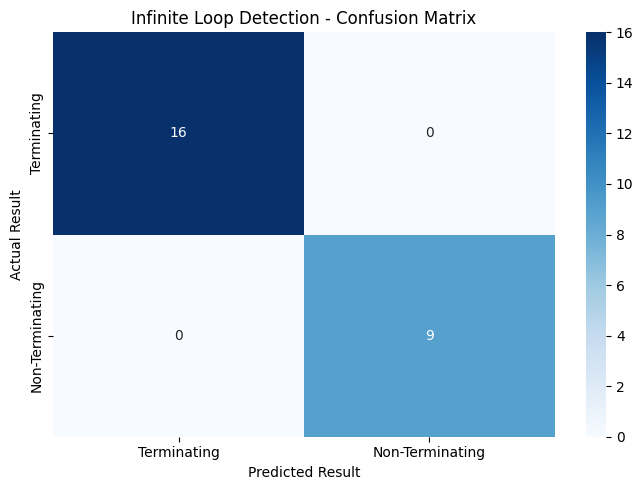


STEP 8 COMPLETED!


In [23]:

# ============================================================
# STEP 8: MODEL EVALUATION AND PERFORMANCE METRICS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Convert loop-level results into program-level predictions
def classify_program(group):

    results = group["Detection Result"].tolist()

    if any(r in ["Infinite", "Likely Infinite"] for r in results):
        return "Non-Terminating"

    if all(r == "Finite" for r in results):
        return "Terminating"

    return "Unknown"


predictions = (
    loop_features_df.groupby("Program ID")
    .apply(classify_program)
    .reset_index(name="Predicted Result")
)

# Obtain actual expected results
actual = development_data[
    ["program_id", "program_name", "expected_result"]
].copy()

actual.columns = [
    "Program ID", "Program Name", "Expected Result"
]

# Merge actual and predicted results
evaluation_df = actual.merge(
    predictions,
    on="Program ID",
    how="left"
)

# Calculate evaluation metrics
y_true = evaluation_df["Expected Result"]
y_pred = evaluation_df["Predicted Result"]

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred,
    pos_label="Non-Terminating",
    zero_division=0
)
recall = recall_score(
    y_true, y_pred,
    pos_label="Non-Terminating",
    zero_division=0
)
f1 = f1_score(
    y_true, y_pred,
    pos_label="Non-Terminating",
    zero_division=0
)

# Display program-level comparison
print("=" * 75)
print("PROGRAM-LEVEL PREDICTION RESULTS")
print("=" * 75)

display(evaluation_df)

# Performance metrics
metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Value": [accuracy, precision, recall, f1]
})

print("\nMODEL PERFORMANCE METRICS")
print("=" * 75)

display(metrics_df)

# Detailed classification report
print("\nCLASSIFICATION REPORT")
print("=" * 75)

print(classification_report(
    y_true,
    y_pred,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=["Terminating", "Non-Terminating"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Terminating", "Non-Terminating"],
    yticklabels=["Terminating", "Non-Terminating"]
)

plt.title("Infinite Loop Detection - Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

print("\nSTEP 8 COMPLETED!")


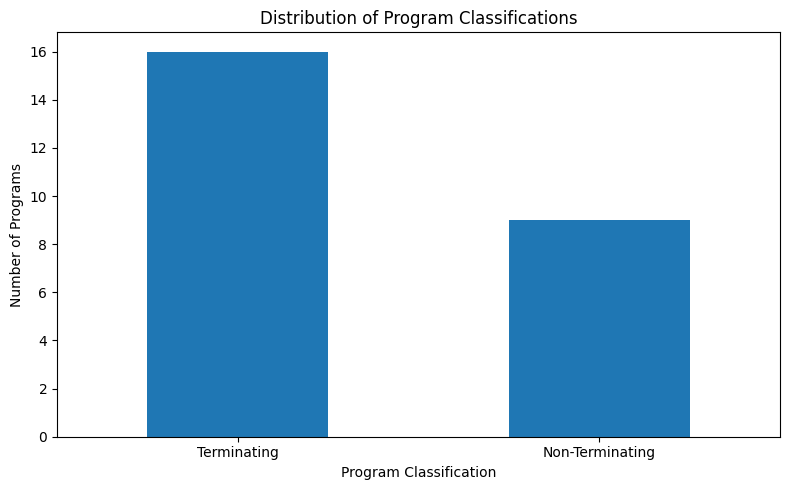

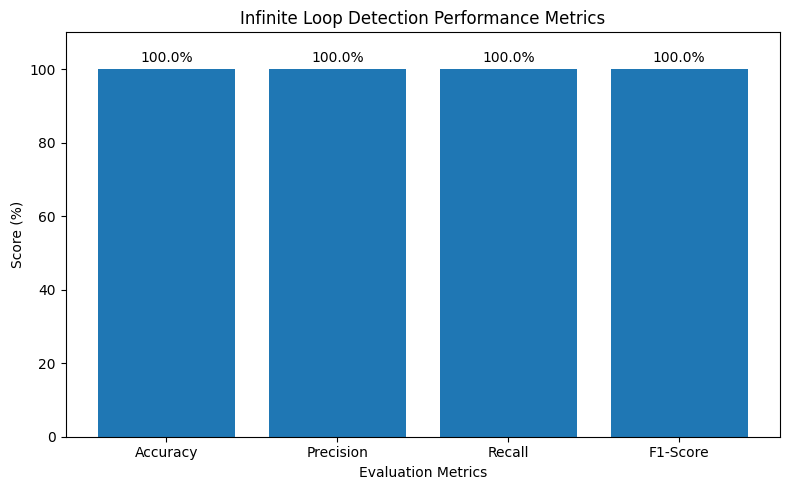

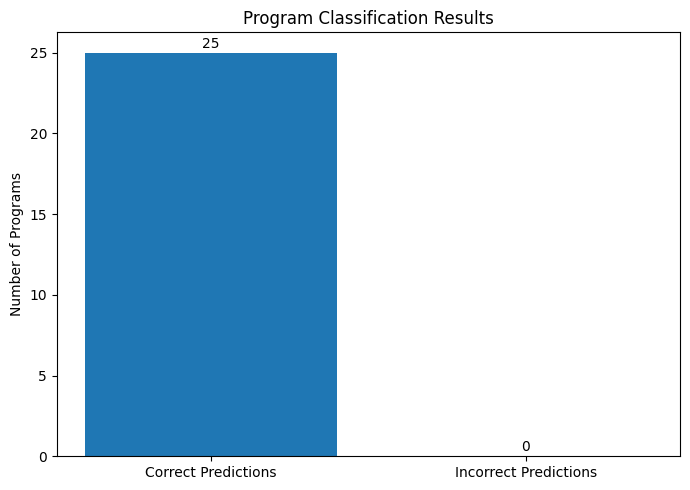

PROJECT VISUALIZATION AND EXPORT COMPLETED
Total Programs: 25
Correct Predictions: 25
Incorrect Predictions: 0
Accuracy: 100.0 %

Generated Files:
- classification_distribution.png
- program_predictions.csv
- performance_metrics.png
- loop_features.csv
- prediction_comparison.csv
- prediction_results.png
- performance_metrics.csv

STEP 9 COMPLETED!


In [24]:

# ============================================================
# STEP 9: PROJECT VISUALIZATION AND RESULT EXPORT
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import os

os.makedirs("project_outputs", exist_ok=True)

# 1. Classification Distribution
classification_counts = evaluation_df[
    "Expected Result"
].value_counts()

plt.figure(figsize=(8, 5))
classification_counts.plot(
    kind="bar",
    title="Distribution of Program Classifications"
)
plt.xlabel("Program Classification")
plt.ylabel("Number of Programs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("project_outputs/classification_distribution.png", dpi=300)
plt.show()


# 2. Performance Metrics Graph
plt.figure(figsize=(8, 5))

plt.bar(
    metrics_df["Metric"],
    metrics_df["Value"] * 100
)

plt.title("Infinite Loop Detection Performance Metrics")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 110)

for i, value in enumerate(metrics_df["Value"]):
    plt.text(i, value * 100 + 2, f"{value*100:.1f}%",
             ha="center")

plt.tight_layout()
plt.savefig("project_outputs/performance_metrics.png", dpi=300)
plt.show()


# 3. Actual vs Predicted Results
comparison = evaluation_df[
    ["Program ID", "Expected Result", "Predicted Result"]
].copy()

comparison["Correct Prediction"] = (
    comparison["Expected Result"] ==
    comparison["Predicted Result"]
)

correct = comparison["Correct Prediction"].sum()
incorrect = len(comparison) - correct

plt.figure(figsize=(7, 5))

plt.bar(
    ["Correct Predictions", "Incorrect Predictions"],
    [correct, incorrect]
)

plt.title("Program Classification Results")
plt.ylabel("Number of Programs")

for i, value in enumerate([correct, incorrect]):
    plt.text(i, value + 0.3, str(value), ha="center")

plt.tight_layout()
plt.savefig("project_outputs/prediction_results.png", dpi=300)
plt.show()


# 4. Export project results
evaluation_df.to_csv(
    "project_outputs/program_predictions.csv",
    index=False
)

loop_features_df.to_csv(
    "project_outputs/loop_features.csv",
    index=False
)

metrics_df.to_csv(
    "project_outputs/performance_metrics.csv",
    index=False
)

comparison.to_csv(
    "project_outputs/prediction_comparison.csv",
    index=False
)

print("=" * 70)
print("PROJECT VISUALIZATION AND EXPORT COMPLETED")
print("=" * 70)

print("Total Programs:", len(evaluation_df))
print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nGenerated Files:")
for file in os.listdir("project_outputs"):
    print("-", file)

print("\nSTEP 9 COMPLETED!")


INDEPENDENT TEST DATASET


,test_id,program_name,code,expected_result
0,1,Test Increment Loop,x = 0\nwhile x < 6:\n x += 1,Terminating
1,2,Test Countdown by Two,x = 10\nwhile x > 0:\n x -= 2,Terminating
2,3,Test Positive Infinite Counter,x = 1\nwhile x > 0:\n x += 2,Non-Terminating
3,4,Test Zero Iteration,x = 5\nwhile x < 0:\n x += 1,Terminating
4,5,Test Equality Countdown,x = 3\nwhile x != 0:\n x -= 1,Terminating
5,6,Test Increasing Equality Loop,x = 2\nwhile x >= 2:\n x += 1,Non-Terminating
6,7,Test Multiplication Loop,x = 1\nwhile x < 8:\n x *= 2,Terminating
7,8,Test Constant Multiplication,x = 1\nwhile x < 8:\n x *= 1,Non-Terminating
8,9,Test Decrement Until Limit,x = 10\nwhile x > 3:\n x -= 3,Terminating
9,10,Test Increment by Three,x = 0\nwhile x < 10:\n x += 3,Terminating


Total Test Programs: 30

Expected Classification Distribution:


,count
expected_result,
Terminating,22
Non-Terminating,8



INDEPENDENT TEST PREDICTION RESULTS


,test_id,program_name,code,expected_result,predicted_result,detection_reason
0,1,Test Increment Loop,x = 0\nwhile x < 6:\n x += 1,Terminating,Terminating,Loop condition became false
1,2,Test Countdown by Two,x = 10\nwhile x > 0:\n x -= 2,Terminating,Terminating,Loop condition became false
2,3,Test Positive Infinite Counter,x = 1\nwhile x > 0:\n x += 2,Non-Terminating,Non-Terminating,Iteration safety limit reached
3,4,Test Zero Iteration,x = 5\nwhile x < 0:\n x += 1,Terminating,Terminating,Loop condition became false
4,5,Test Equality Countdown,x = 3\nwhile x != 0:\n x -= 1,Terminating,Terminating,Loop condition became false
5,6,Test Increasing Equality Loop,x = 2\nwhile x >= 2:\n x += 1,Non-Terminating,Non-Terminating,Iteration safety limit reached
6,7,Test Multiplication Loop,x = 1\nwhile x < 8:\n x *= 2,Terminating,Terminating,Loop condition became false
7,8,Test Constant Multiplication,x = 1\nwhile x < 8:\n x *= 1,Non-Terminating,Non-Terminating,Iteration safety limit reached
8,9,Test Decrement Until Limit,x = 10\nwhile x > 3:\n x -= 3,Terminating,Terminating,Loop condition became false
9,10,Test Increment by Three,x = 0\nwhile x < 10:\n x += 3,Terminating,Terminating,Loop condition became false



INDEPENDENT TEST PERFORMANCE


,Metric,Value
0,Accuracy,1.0
1,Precision,1.0
2,Recall,1.0
3,F1-Score,1.0
4,Classification Coverage,1.0



CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Non-Terminating       1.00      1.00      1.00         8
    Terminating       1.00      1.00      1.00        22

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



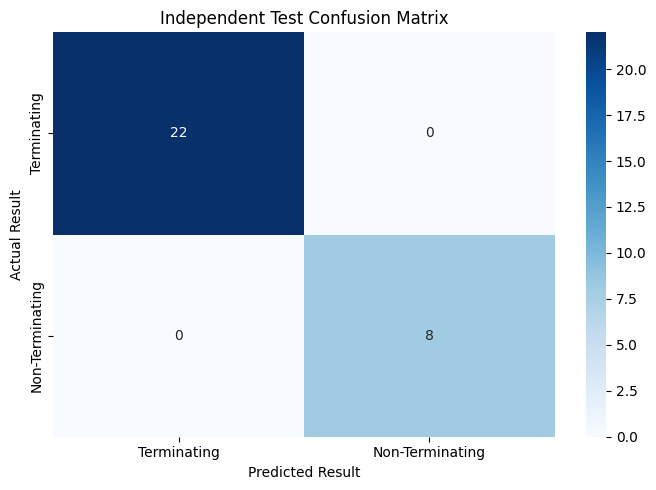


STEP 11 COMPLETED!
Total Test Programs: 30
Successfully Classified: 30
Unknown Predictions: 0


In [25]:

# ============================================================
# STEP 11: CREATE INDEPENDENT TEST DATASET (30 PROGRAMS)
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import os

test_programs = [

    (1, "Test Increment Loop",
     "x = 0\nwhile x < 6:\n    x += 1", "Terminating"),

    (2, "Test Countdown by Two",
     "x = 10\nwhile x > 0:\n    x -= 2", "Terminating"),

    (3, "Test Positive Infinite Counter",
     "x = 1\nwhile x > 0:\n    x += 2", "Non-Terminating"),

    (4, "Test Zero Iteration",
     "x = 5\nwhile x < 0:\n    x += 1", "Terminating"),

    (5, "Test Equality Countdown",
     "x = 3\nwhile x != 0:\n    x -= 1", "Terminating"),

    (6, "Test Increasing Equality Loop",
     "x = 2\nwhile x >= 2:\n    x += 1", "Non-Terminating"),

    (7, "Test Multiplication Loop",
     "x = 1\nwhile x < 8:\n    x *= 2", "Terminating"),

    (8, "Test Constant Multiplication",
     "x = 1\nwhile x < 8:\n    x *= 1", "Non-Terminating"),

    (9, "Test Decrement Until Limit",
     "x = 10\nwhile x > 3:\n    x -= 3", "Terminating"),

    (10, "Test Increment by Three",
     "x = 0\nwhile x < 10:\n    x += 3", "Terminating"),

    (11, "Test Direct Variable Reset",
     "x = 5\nwhile x > 0:\n    x = 0", "Terminating"),

    (12, "Test Conditional Break",
     "x = 0\nwhile x < 5:\n    if x == 3:\n        break\n    x += 1", "Terminating"),

    (13, "Test Break After Increment",
     "x = 0\nwhile x < 5:\n    x += 1\n    if x == 3:\n        break", "Terminating"),

    (14, "Test Conditional Branch Break",
     "x = 0\nwhile x < 5:\n    if x < 3:\n        x += 1\n    else:\n        break", "Terminating"),

    (15, "Test Counter With Break",
     "x = 1\nwhile x > 0:\n    if x == 3:\n        break\n    x += 1", "Terminating"),

    (16, "Test Repeating Variable Cycle",
     "x = 1\nwhile x > 0:\n    if x == 3:\n        x = 1\n    x += 1", "Non-Terminating"),

    (17, "Test Continue With Increment",
     "x = 0\nwhile x < 4:\n    x += 1\n    continue", "Terminating"),

    (18, "Test Continue Without Update",
     "x = 1\nwhile x > 0:\n    continue", "Non-Terminating"),

    (19, "Test Conditional Decrement",
     "x = 5\nwhile x > 0:\n    if x > 2:\n        x -= 1\n    else:\n        x = 0", "Terminating"),

    (20, "Test Conditional Continue",
     "x = 0\nwhile x < 10:\n    if x == 4:\n        x += 1\n        continue\n    x += 2", "Terminating"),

    (21, "Test Odd Increment",
     "x = 1\nwhile x < 10:\n    x += 2", "Terminating"),

    (22, "Test Zero Decrement",
     "x = 1\nwhile x > 0:\n    x -= 0", "Non-Terminating"),

    (23, "Test Less Than Equal Loop",
     "x = 0\nwhile x <= 5:\n    x += 1", "Terminating"),

    (24, "Test Nonnegative Infinite Loop",
     "x = 0\nwhile x >= 0:\n    x += 1", "Non-Terminating"),

    (25, "Test Equality Decrement",
     "x = 10\nwhile x != 4:\n    x -= 2", "Terminating"),

    (26, "Test Equality Increment",
     "x = 0\nwhile x != 5:\n    x += 1", "Terminating"),

    (27, "Test Constant Variable Loop",
     "x = 5\nwhile x > 0:\n    x += 0", "Non-Terminating"),

    (28, "Test Small Finite Loop",
     "x = 0\nwhile x < 3:\n    x += 1", "Terminating"),

    (29, "Test Conditional Exit",
     "x = 2\nwhile x > 0:\n    if x == 1:\n        break\n    x -= 1", "Terminating"),

    (30, "Test Conditional Countdown",
     "x = 2\nwhile x > 0:\n    if x == 2:\n        x -= 1\n    else:\n        x -= 1", "Terminating")
]

# Create independent testing DataFrame
test_dataset = pd.DataFrame(
    test_programs,
    columns=[
        "test_id",
        "program_name",
        "code",
        "expected_result"
    ]
)

print("=" * 75)
print("INDEPENDENT TEST DATASET")
print("=" * 75)

display(test_dataset)

print("Total Test Programs:", len(test_dataset))
print("\nExpected Classification Distribution:")
display(test_dataset["expected_result"].value_counts())


# ============================================================
# RUN THE DETECTOR ON THE NEW TEST PROGRAMS
# ============================================================

test_predictions = []
test_reasons = []

for _, row in test_dataset.iterrows():

    result, reason = analyze_source_code(row["code"])

    if result == "Likely Infinite":
        predicted = "Non-Terminating"
    elif result == "Finite":
        predicted = "Terminating"
    else:
        predicted = "Unknown"

    test_predictions.append(predicted)
    test_reasons.append(reason)

test_dataset["predicted_result"] = test_predictions
test_dataset["detection_reason"] = test_reasons

# ============================================================
# INDEPENDENT TEST EVALUATION
# ============================================================

y_true_test = test_dataset["expected_result"]
y_pred_test = test_dataset["predicted_result"]

# Evaluate only successfully classified programs
valid = y_pred_test != "Unknown"

if valid.sum() > 0:

    accuracy_test = accuracy_score(
        y_true_test[valid], y_pred_test[valid]
    )

    precision_test = precision_score(
        y_true_test[valid], y_pred_test[valid],
        pos_label="Non-Terminating",
        zero_division=0
    )

    recall_test = recall_score(
        y_true_test[valid], y_pred_test[valid],
        pos_label="Non-Terminating",
        zero_division=0
    )

    f1_test = f1_score(
        y_true_test[valid], y_pred_test[valid],
        pos_label="Non-Terminating",
        zero_division=0
    )

    print("\n" + "=" * 75)
    print("INDEPENDENT TEST PREDICTION RESULTS")
    print("=" * 75)

    display(test_dataset)

    print("\nINDEPENDENT TEST PERFORMANCE")

    test_metrics_df = pd.DataFrame({
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "Classification Coverage"
        ],
        "Value": [
            accuracy_test,
            precision_test,
            recall_test,
            f1_test,
            valid.mean()
        ]
    })

    display(test_metrics_df)

    print("\nCLASSIFICATION REPORT")

    print(classification_report(
        y_true_test[valid],
        y_pred_test[valid],
        zero_division=0
    ))

    # Confusion matrix
    cm_test = confusion_matrix(
        y_true_test[valid],
        y_pred_test[valid],
        labels=["Terminating", "Non-Terminating"]
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm_test,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Terminating", "Non-Terminating"],
        yticklabels=["Terminating", "Non-Terminating"]
    )

    plt.title("Independent Test Confusion Matrix")
    plt.xlabel("Predicted Result")
    plt.ylabel("Actual Result")
    plt.tight_layout()
    plt.show()

else:
    print("No programs were successfully classified.")

# Save independent test results
os.makedirs("project_outputs", exist_ok=True)

test_dataset.to_csv(
    "project_outputs/independent_test_results.csv",
    index=False
)

if valid.sum() > 0:
    test_metrics_df.to_csv(
        "project_outputs/independent_test_metrics.csv",
        index=False
    )

print("\n" + "=" * 75)
print("STEP 11 COMPLETED!")
print("Total Test Programs:", len(test_dataset))
print("Successfully Classified:", valid.sum())
print("Unknown Predictions:", (~valid).sum())
print("=" * 75)


DEVELOPMENT VS INDEPENDENT TEST PERFORMANCE


,Metric,Development Dataset,Independent Test Dataset
0,Accuracy,1.0,1.0
1,Precision,1.0,1.0
2,Recall,1.0,1.0
3,F1-Score,1.0,1.0


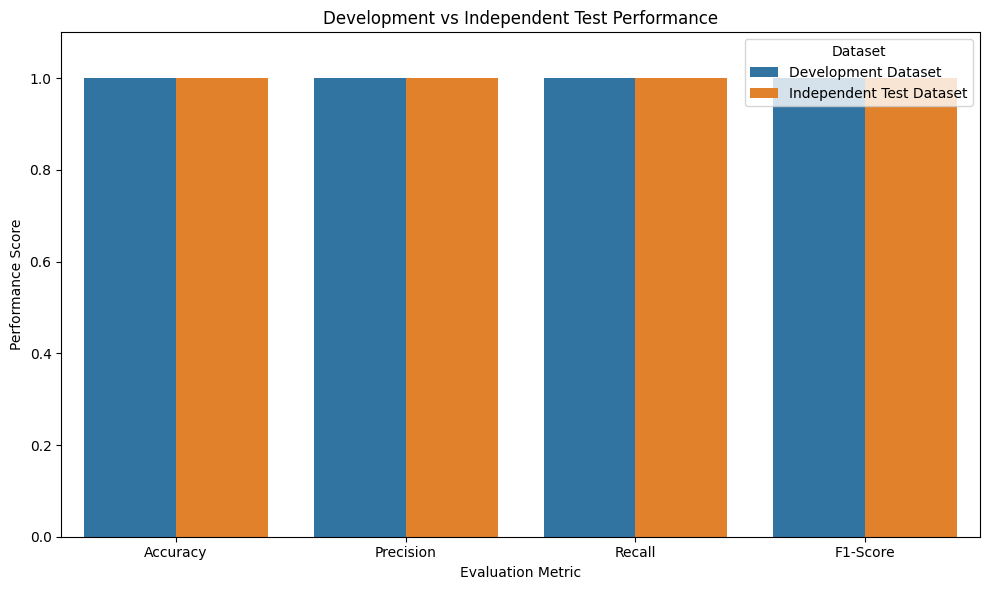

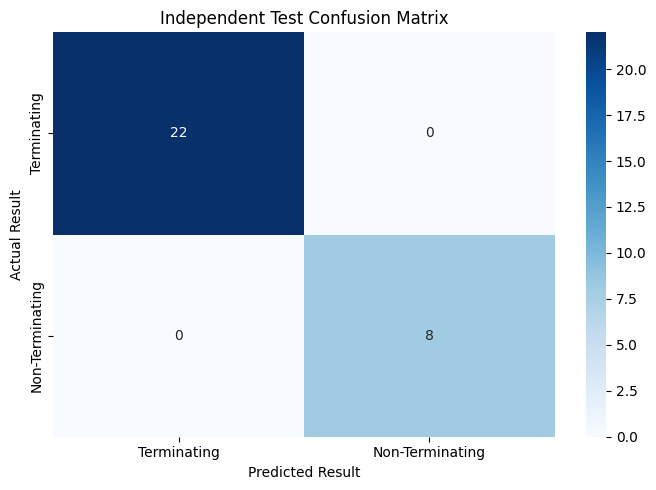

Generated:
1. development_vs_test_comparison.png
2. development_vs_test_metrics.csv
3. independent_test_confusion_matrix.png

STEP 12 COMPLETED!


In [26]:

# ============================================================
# STEP 12: DEVELOPMENT VS INDEPENDENT TEST COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("project_outputs", exist_ok=True)

# Combine both evaluation results
comparison_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Development Dataset": [accuracy, precision, recall, f1],
    "Independent Test Dataset": [
        accuracy_test, precision_test, recall_test, f1_test
    ]
})

print("=" * 70)
print("DEVELOPMENT VS INDEPENDENT TEST PERFORMANCE")
print("=" * 70)

display(comparison_metrics)

# Convert data for plotting
plot_data = comparison_metrics.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

# Performance comparison graph
plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Dataset"
)

plt.ylim(0, 1.1)
plt.title("Development vs Independent Test Performance")
plt.ylabel("Performance Score")
plt.xlabel("Evaluation Metric")
plt.tight_layout()

plt.savefig(
    "project_outputs/development_vs_test_comparison.png",
    dpi=300
)

plt.show()

# Save comparison table
comparison_metrics.to_csv(
    "project_outputs/development_vs_test_metrics.csv",
    index=False
)

# Save independent test confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Terminating", "Non-Terminating"],
    yticklabels=["Terminating", "Non-Terminating"]
)

plt.title("Independent Test Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()

plt.savefig(
    "project_outputs/independent_test_confusion_matrix.png",
    dpi=300
)

plt.show()

print("Generated:")
print("1. development_vs_test_comparison.png")
print("2. development_vs_test_metrics.csv")
print("3. independent_test_confusion_matrix.png")

print("\nSTEP 12 COMPLETED!")


In [27]:

# ============================================================
# STEP 13: FINAL PROJECT PACKAGE FOR GITHUB
# ============================================================

import os
import shutil
import zipfile
import pandas as pd
from google.colab import files

project_name = "Infinite_Loop_Detection_System"
base_dir = f"/content/{project_name}"

# Remove old folder if it exists
if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

# Create project folders
os.makedirs(f"{base_dir}/dataset", exist_ok=True)
os.makedirs(f"{base_dir}/results", exist_ok=True)
os.makedirs(f"{base_dir}/graphs", exist_ok=True)

# ------------------------------------------------------------
# 1. SAVE DATASETS
# ------------------------------------------------------------

dataset.to_csv(
    f"{base_dir}/dataset/complete_dataset.csv", index=False
)

development_data.to_csv(
    f"{base_dir}/dataset/development_dataset.csv", index=False
)

test_dataset.to_csv(
    f"{base_dir}/dataset/independent_test_dataset.csv", index=False
)

# ------------------------------------------------------------
# 2. SAVE ANALYSIS RESULTS
# ------------------------------------------------------------

loop_features_df.to_csv(
    f"{base_dir}/results/loop_features.csv", index=False
)

evaluation_df.to_csv(
    f"{base_dir}/results/development_predictions.csv", index=False
)

comparison.to_csv(
    f"{base_dir}/results/development_prediction_comparison.csv",
    index=False
)

test_dataset.to_csv(
    f"{base_dir}/results/independent_test_predictions.csv",
    index=False
)

comparison_metrics.to_csv(
    f"{base_dir}/results/development_vs_test_metrics.csv",
    index=False
)

test_metrics_df.to_csv(
    f"{base_dir}/results/independent_test_metrics.csv",
    index=False
)

# ------------------------------------------------------------
# 3. COPY ALL GENERATED GRAPHS
# ------------------------------------------------------------

graph_files = [
    "classification_distribution.png",
    "performance_metrics.png",
    "prediction_results.png",
    "confusion_matrix.png",
    "development_vs_test_comparison.png",
    "independent_test_confusion_matrix.png"
]

for filename in graph_files:
    source = f"/content/project_outputs/{filename}"

    if os.path.exists(source):
        shutil.copy2(
            source,
            f"{base_dir}/graphs/{filename}"
        )
        print("Added graph:", filename)
    else:
        print("Not found, skipped:", filename)

# ------------------------------------------------------------
# 4. CREATE README
# ------------------------------------------------------------

readme = """
# Infinite Loop Detection System

## Project Information
- Subject: Formal Language and Automata Theory
- Project: Task 4 - Infinite Loop Detection System
- Environment: Google Colab
- Language: Python
- Version: 1.0

## Project Description

The Infinite Loop Detection System is a Python-based prototype
that analyzes loop structures in Python programs and classifies
them as Terminating or Non-Terminating.

It uses Abstract Syntax Tree (AST) analysis, loop feature
extraction, rule-based classification, and restricted execution
simulation.

## Main Features

1. Python source code analysis using AST.
2. Identification of while and for loops.
3. Extraction of loop conditions and modified variables.
4. Detection of break and continue statements.
5. Restricted loop simulation.
6. Program-level classification.
7. Performance evaluation.
8. Confusion matrix and graphical analysis.

## Dataset Information

- Development programs: 25
- Independent test programs: 30
- Total evaluated programs: 55
- Development loop records: 27

## Evaluation Results

Development Dataset:
- Accuracy: 100%
- Precision: 100%
- Recall: 100%
- F1-score: 100%

Independent Test Dataset:
- Accuracy: 100%
- Precision: 100%
- Recall: 100%
- F1-score: 100%

These results apply only to the manually designed examples
included in this project. They should not be interpreted as
proof of general-purpose loop termination detection.

## Important Limitation

The system uses restricted AST-based simulation and a maximum
iteration safety limit. Reaching this limit indicates that the
program did not terminate within the simulation limit; it does
not mathematically prove that the loop is infinite.

The prototype does not support every Python language construct
or every possible program structure.

## Project Structure

Infinite_Loop_Detection_System/
|
|-- dataset/
|   |-- complete_dataset.csv
|   |-- development_dataset.csv
|   |-- independent_test_dataset.csv
|
|-- results/
|   |-- loop_features.csv
|   |-- development_predictions.csv
|   |-- development_prediction_comparison.csv
|   |-- independent_test_predictions.csv
|   |-- independent_test_metrics.csv
|   |-- development_vs_test_metrics.csv
|
|-- graphs/
|   |-- classification_distribution.png
|   |-- performance_metrics.png
|   |-- prediction_results.png
|   |-- confusion_matrix.png
|   |-- development_vs_test_comparison.png
|   |-- independent_test_confusion_matrix.png
|
|-- README.md
|-- requirements.txt

## Libraries

- pandas
- numpy
- matplotlib
- seaborn
- scikit-learn

## Future Enhancements

- Support for more complex nested loops.
- Improved handling of conditional branches.
- Symbolic execution.
- Static analysis of additional Python constructs.
- Testing with larger external benchmark datasets.
"""

with open(f"{base_dir}/README.md", "w") as f:
    f.write(readme)

# ------------------------------------------------------------
# 5. CREATE REQUIREMENTS FILE
# ------------------------------------------------------------

requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
"""

with open(f"{base_dir}/requirements.txt", "w") as f:
    f.write(requirements.strip())

# ------------------------------------------------------------
# 6. CREATE ZIP FILE
# ------------------------------------------------------------

zip_name = f"/content/{project_name}.zip"

if os.path.exists(zip_name):
    os.remove(zip_name)

shutil.make_archive(
    f"/content/{project_name}",
    "zip",
    "/content",
    project_name
)

print("\n" + "=" * 65)
print("FINAL PROJECT PACKAGE CREATED")
print("=" * 65)

for root, dirs, filenames in os.walk(base_dir):
    for filename in filenames:
        print(os.path.relpath(
            os.path.join(root, filename), base_dir
        ))

print("\nZIP FILE:", zip_name)
print("STEP 13 COMPLETED!")

files.download(zip_name)


Added graph: classification_distribution.png
Added graph: performance_metrics.png
Added graph: prediction_results.png
Not found, skipped: confusion_matrix.png
Added graph: development_vs_test_comparison.png
Added graph: independent_test_confusion_matrix.png

FINAL PROJECT PACKAGE CREATED
README.md
requirements.txt
graphs/classification_distribution.png
graphs/performance_metrics.png
graphs/prediction_results.png
graphs/independent_test_confusion_matrix.png
graphs/development_vs_test_comparison.png
results/development_prediction_comparison.csv
results/loop_features.csv
results/independent_test_metrics.csv
results/development_predictions.csv
results/development_vs_test_metrics.csv
results/independent_test_predictions.csv
dataset/independent_test_dataset.csv
dataset/development_dataset.csv
dataset/complete_dataset.csv

ZIP FILE: /content/Infinite_Loop_Detection_System.zip
STEP 13 COMPLETED!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>